# Random Forest and XGBoost Comparison Using SHAP for Osteoporosis Risk Classification

## 1. Pengambilan Dataset

In [ ]:
!pip install kagglehub -q
import kagglehub

In [ ]:
path = kagglehub.dataset_download("amitvkulkarni/lifestyle-factors-influencing-osteoporosis")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'lifestyle-factors-influencing-osteoporosis' dataset.
Path to dataset files: /kaggle/input/lifestyle-factors-influencing-osteoporosis


In [ ]:
import os
print(os.listdir(path))

['osteoporosis.csv']


## 2. Memuat Data ke DataFrame

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# Sesuaikan nama file csv-nya berdasarkan hasil Cell 3
df = pd.read_csv(f"{path}/osteoporosis.csv")
print(df.shape)
df.head()

(1958, 16)


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,1734616,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,1419098,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,1797916,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,1805337,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,1351334,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1


## 3. Eksplorasi Data Awal (EDA)

In [ ]:
df.info()
print()
print("Missing value per kolom:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 non-null   object
 9   Physical Activity    1958 non-null   object
 10  Smoking              1958 non-null   object
 11  Alcohol Consumption  970 non-null    object
 12  Medical Conditions   1311 non-null   object
 13  Medications          973 non-null    object
 14  Prior Fractures      1958 non-null   object
 15  Osteoporosis         1958 non-null   int64 
dtypes: int

**Distribusi kelas target (Osteoporosis):**

In [ ]:
print(df['Osteoporosis'].value_counts())

Osteoporosis
1    979
0    979
Name: count, dtype: int64


## 4. Data Cleaning

Nilai kosong (NaN) pada kolom berikut kemungkinan besar bermakna "tidak ada/tidak mengonsumsi", bukan data yang hilang secara acak, sehingga diisi dengan label `'None'`, bukan dihapus.

In [ ]:
# NaN di kolom ini kemungkinan besar bermakna "tidak ada/tidak mengonsumsi", bukan data hilang acak
cols_to_fill = ['Alcohol Consumption', 'Medical Conditions', 'Medications']

for col in cols_to_fill:
    df[col] = df[col].fillna('None')

print(df[cols_to_fill].isna().sum())

Alcohol Consumption    0
Medical Conditions     0
Medications            0
dtype: int64


Kolom `Id` dihapus karena hanya identifier, tidak relevan sebagai fitur prediktor.

In [ ]:
df = df.drop(columns=['Id'])
print(df.columns.tolist())

['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']


In [ ]:
# Cek duplikat SETELAH Id dibuang (Id unik, jadi harus dicek tanpa Id)
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 4


“4 baris identik pada seluruh atribut dipertahankan karena memiliki Id berbeda.”

## 5. Encoding Fitur Kategorikal

Mengecek kategori unik pada tiap kolom bertipe object sebelum menentukan strategi encoding.

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()

for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

Gender: ['Female' 'Male']
Hormonal Changes: ['Normal' 'Postmenopausal']
Family History: ['Yes' 'No']
Race/Ethnicity: ['Asian' 'Caucasian' 'African American']
Body Weight: ['Underweight' 'Normal']
Calcium Intake: ['Low' 'Adequate']
Vitamin D Intake: ['Sufficient' 'Insufficient']
Physical Activity: ['Sedentary' 'Active']
Smoking: ['Yes' 'No']
Alcohol Consumption: ['Moderate' 'None']
Medical Conditions: ['Rheumatoid Arthritis' 'None' 'Hyperthyroidism']
Medications: ['Corticosteroids' 'None']
Prior Fractures: ['Yes' 'No']


Kolom dikelompokkan menjadi fitur biner (di-*label encode*) dan fitur multi-kategori (di-*one-hot encode*).

In [ ]:
binary_cols = ['Gender', 'Hormonal Changes', 'Family History', 'Body Weight',
               'Calcium Intake', 'Vitamin D Intake', 'Physical Activity',
               'Smoking', 'Alcohol Consumption', 'Medications', 'Prior Fractures']

multi_cols = ['Race/Ethnicity', 'Medical Conditions']

**Label Encoding** untuk fitur biner:

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
label_encoders = {}

for col in binary_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

df_encoded.head()

,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,69,0,0,1,Asian,1,1,1,1,1,0,Rheumatoid Arthritis,0,1,1
1,32,0,0,1,Asian,1,1,1,1,0,1,None,1,1,1
2,89,0,1,0,Caucasian,0,0,1,0,0,0,Hyperthyroidism,0,0,1
3,78,0,0,0,Caucasian,1,0,0,1,1,1,Rheumatoid Arthritis,0,0,1
4,38,1,1,1,African American,0,1,1,0,1,1,Rheumatoid Arthritis,1,1,1


**Keterangan Mapping Encoding (0/1)**

Berikut makna asli dari tiap angka hasil Label Encoding, diambil langsung dari `label_encoders` yang tersimpan.

In [ ]:
# Loop untuk setiap kolom biner yang sudah di-encode sebelumnya
for col in binary_cols:
    # label_encoders[col] menyimpan objek LabelEncoder yang sudah di-fit untuk kolom ini
    # .classes_ berisi label ASLI (teks) sebelum diubah jadi angka, misal ['Female', 'Male']
    # .transform(...) mengubah label asli itu menjadi angka hasil encoding (0, 1, dst)
    # zip(...) memasangkan tiap label asli dengan angka hasil encoding-nya
    # dict(...) mengubah pasangan tersebut jadi dictionary, contoh: {'Female': 0, 'Male': 1}
    mapping = dict(zip(label_encoders[col].classes_, label_encoders[col].transform(label_encoders[col].classes_)))

    # Cetak nama kolom beserta mapping-nya, supaya kita tahu persis
    # angka 0 dan 1 pada kolom tersebut mewakili kategori apa
    print(f"{col}: {mapping}")

Gender: {'Female': np.int64(0), 'Male': np.int64(1)}
Hormonal Changes: {'Normal': np.int64(0), 'Postmenopausal': np.int64(1)}
Family History: {'No': np.int64(0), 'Yes': np.int64(1)}
Body Weight: {'Normal': np.int64(0), 'Underweight': np.int64(1)}
Calcium Intake: {'Adequate': np.int64(0), 'Low': np.int64(1)}
Vitamin D Intake: {'Insufficient': np.int64(0), 'Sufficient': np.int64(1)}
Physical Activity: {'Active': np.int64(0), 'Sedentary': np.int64(1)}
Smoking: {'No': np.int64(0), 'Yes': np.int64(1)}
Alcohol Consumption: {'Moderate': np.int64(0), 'None': np.int64(1)}
Medications: {'Corticosteroids': np.int64(0), 'None': np.int64(1)}
Prior Fractures: {'No': np.int64(0), 'Yes': np.int64(1)}


**One-Hot Encoding** untuk fitur multi-kategori:

In [ ]:
df_encoded = pd.get_dummies(df_encoded, columns=multi_cols, drop_first=False)

print(df_encoded.shape)
df_encoded.head()

(1958, 19)


,Age,Gender,Hormonal Changes,Family History,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medications,Prior Fractures,Osteoporosis,Race/Ethnicity_African American,Race/Ethnicity_Asian,Race/Ethnicity_Caucasian,Medical Conditions_Hyperthyroidism,Medical Conditions_None,Medical Conditions_Rheumatoid Arthritis
0,69,0,0,1,1,1,1,1,1,0,0,1,1,False,True,False,False,False,True
1,32,0,0,1,1,1,1,1,0,1,1,1,1,False,True,False,False,True,False
2,89,0,1,0,0,0,1,0,0,0,0,0,1,False,False,True,True,False,False
3,78,0,0,0,1,0,0,1,1,1,0,0,1,False,False,True,False,False,True
4,38,1,1,1,0,1,1,0,1,1,1,1,1,True,False,False,False,False,True


In [ ]:
print(df_encoded.columns.tolist())
print()
print(df_encoded.dtypes)

['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medications', 'Prior Fractures', 'Osteoporosis', 'Race/Ethnicity_African American', 'Race/Ethnicity_Asian', 'Race/Ethnicity_Caucasian', 'Medical Conditions_Hyperthyroidism', 'Medical Conditions_None', 'Medical Conditions_Rheumatoid Arthritis']

Age                                        int64
Gender                                     int64
Hormonal Changes                           int64
Family History                             int64
Body Weight                                int64
Calcium Intake                             int64
Vitamin D Intake                           int64
Physical Activity                          int64
Smoking                                    int64
Alcohol Consumption                        int64
Medications                                int64
Prior Fractures                            int64
Os

## 6. Pemisahan Fitur, Target, dan Train-Test Split

In [ ]:
X = df_encoded.drop(columns=['Osteoporosis'])
y = df_encoded['Osteoporosis']

print(X.shape, y.shape)

(1958, 18) (1958,)


Split data 80:20 dengan `stratify=y` untuk menjaga proporsi kelas tetap seimbang pada data latih maupun data uji.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Distribusi train:", y_train.value_counts().to_dict())
print("Distribusi test:", y_test.value_counts().to_dict())

Train: (1566, 18) | Test: (392, 18)
Distribusi train: {0: 783, 1: 783}
Distribusi test: {1: 196, 0: 196}


## 7. Pemodelan: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Performance:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance:
              precision    recall  f1-score   support

           0       0.76      0.95      0.85       196
           1       0.93      0.70      0.80       196

    accuracy                           0.83       392
   macro avg       0.85      0.83      0.82       392
weighted avg       0.85      0.83      0.82       392



## 8. Pemodelan: XGBoost

In [ ]:
!pip install xgboost -q
from xgboost import XGBClassifier

xgb_model = XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Performance:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Performance:
              precision    recall  f1-score   support

           0       0.81      0.93      0.87       196
           1       0.92      0.79      0.85       196

    accuracy                           0.86       392
   macro avg       0.87      0.86      0.86       392
weighted avg       0.87      0.86      0.86       392



## 9. Validasi Silang (5-Fold Cross-Validation)

Dilakukan sebagai pengecekan tambahan untuk memastikan performa model stabil dan tidak hanya baik pada satu skema split tertentu.

In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores_rf = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')
cv_scores_xgb = cross_val_score(xgb_model, X, y, cv=5, scoring='accuracy')

print("Random Forest CV Accuracy:", cv_scores_rf)
print("Rata-rata:", cv_scores_rf.mean(), "| Std:", cv_scores_rf.std())
print()
print("XGBoost CV Accuracy:", cv_scores_xgb)
print("Rata-rata:", cv_scores_xgb.mean(), "| Std:", cv_scores_xgb.std())

Random Forest CV Accuracy: [0.83163265 0.87244898 0.85969388 0.84143223 0.87468031]
Rata-rata: 0.8559776084346783 | Std: 0.01696556915381763

XGBoost CV Accuracy: [0.83928571 0.90306122 0.91071429 0.85421995 0.88235294]
Rata-rata: 0.8779268229030741 | Std: 0.0275009001171912


## 10. Confusion Matrix

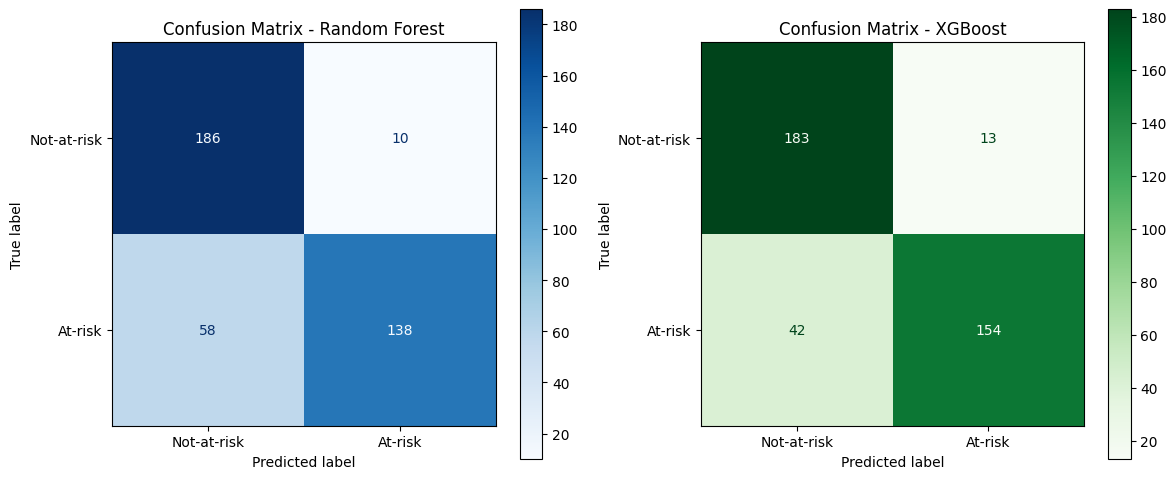

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ['Not-at-risk', 'At-risk']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=labels).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Confusion Matrix - Random Forest')

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
ConfusionMatrixDisplay(cm_xgb, display_labels=labels).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Confusion Matrix - XGBoost')

plt.tight_layout()
plt.savefig('figure_1_confusion_matrix.png', dpi=350, bbox_inches='tight')
plt.show()

## 11. Optimasi Model: Hyperparameter Tuning (GridSearchCV)

Tahap ini mencari kombinasi parameter terbaik untuk Random Forest dan XGBoost menggunakan pencarian grid (*GridSearchCV*) dengan validasi silang 5-fold, untuk melihat apakah performa model baseline pada Bagian 7 dan 8 masih bisa ditingkatkan.

In [ ]:
# Import tool untuk pencarian kombinasi hyperparameter terbaik secara otomatis
from sklearn.model_selection import GridSearchCV

# Definisikan kombinasi parameter yang ingin diuji untuk Random Forest
param_grid_rf = {
    'n_estimators': [100, 200, 300],      # jumlah pohon dalam forest
    'max_depth': [5, 10, 15, None],       # kedalaman maksimum tiap pohon
    'min_samples_split': [2, 5, 10]       # minimal sampel untuk melakukan split
}

# GridSearchCV akan mencoba SEMUA kombinasi di atas, masing-masing divalidasi dengan 5-fold CV
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),  # model dasar yang akan dituning
    param_grid_rf,        # grid kombinasi parameter yang akan dicoba
    cv=5,                 # jumlah fold cross-validation
    scoring='accuracy',   # metrik yang dipakai untuk menilai kombinasi terbaik
    n_jobs=-1              # gunakan semua core CPU yang tersedia agar lebih cepat
)

# Latih GridSearchCV pada data training -> ini otomatis mencoba semua kombinasi parameter
grid_rf.fit(X_train, y_train)

# Tampilkan kombinasi parameter yang menghasilkan skor CV terbaik
print("Best params RF:", grid_rf.best_params_)
print("Best CV score RF:", grid_rf.best_score_)

# Ambil model Random Forest terbaik hasil tuning (sudah otomatis di-fit ulang oleh GridSearchCV)
rf_model_tuned = grid_rf.best_estimator_

# Uji model terbaik ini pada data test yang belum pernah dilihat model
y_pred_rf_tuned = rf_model_tuned.predict(X_test)

print("\nRandom Forest (Tuned) Performance:")
print(classification_report(y_test, y_pred_rf_tuned))

Best params RF: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
Best CV score RF: 0.8627073116135204

Random Forest (Tuned) Performance:
              precision    recall  f1-score   support

           0       0.76      0.98      0.86       196
           1       0.98      0.69      0.81       196

    accuracy                           0.84       392
   macro avg       0.87      0.84      0.83       392
weighted avg       0.87      0.84      0.83       392



In [ ]:
# Definisikan kombinasi parameter yang ingin diuji untuk XGBoost
param_grid_xgb = {
    'n_estimators': [100, 200, 300],    # jumlah pohon/estimator boosting
    'max_depth': [3, 6, 9],             # kedalaman maksimum tiap pohon
    'learning_rate': [0.01, 0.1, 0.2]   # seberapa besar kontribusi tiap pohon baru
}

# Sama seperti Random Forest, coba semua kombinasi dengan validasi silang 5-fold
grid_xgb = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),  # model dasar yang akan dituning
    param_grid_xgb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Latih GridSearchCV -> mencoba seluruh kombinasi parameter pada data training
grid_xgb.fit(X_train, y_train)

# Tampilkan kombinasi parameter terbaik beserta skor CV-nya
print("Best params XGBoost:", grid_xgb.best_params_)
print("Best CV score XGBoost:", grid_xgb.best_score_)

# Ambil model XGBoost terbaik hasil tuning
xgb_model_tuned = grid_xgb.best_estimator_

# Uji model terbaik ini pada data test
y_pred_xgb_tuned = xgb_model_tuned.predict(X_test)

print("\nXGBoost (Tuned) Performance:")
print(classification_report(y_test, y_pred_xgb_tuned))

Best params XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best CV score XGBoost: 0.9157119309741356

XGBoost (Tuned) Performance:
              precision    recall  f1-score   support

           0       0.81      0.99      0.89       196
           1       0.99      0.77      0.87       196

    accuracy                           0.88       392
   macro avg       0.90      0.88      0.88       392
weighted avg       0.90      0.88      0.88       392



## 12. Uji Stabilitas Model dengan Beberapa Random State

Model diuji ulang menggunakan parameter terbaik hasil tuning pada Bagian 11, dengan 5 nilai *random state* yang berbeda untuk memastikan performa model tidak bergantung pada satu skema pembagian data tertentu (bukan hanya kebetulan bagus di satu split).

In [ ]:
# Daftar random_state yang akan diuji, untuk melihat variasi performa model
random_states = [0, 21, 42, 84, 100]

# List kosong untuk menyimpan hasil tiap percobaan
hasil_robustness = []

# Loop untuk setiap nilai random_state
for rs in random_states:
    # Split ulang data train-test dengan random_state yang berbeda tiap iterasi
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=rs, stratify=y)

    # Latih Random Forest dengan parameter TERBAIK hasil tuning (max_depth=5, min_samples_split=5)
    rf_temp = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_split=5, random_state=rs, n_jobs=-1)
    rf_temp.fit(X_tr, y_tr)
    # Hitung akurasi pada data test untuk random_state ini
    acc_rf_temp = accuracy_score(y_te, rf_temp.predict(X_te))

    # Latih XGBoost dengan parameter TERBAIK hasil tuning (max_depth=3, learning_rate=0.1)
    xgb_temp = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=rs, eval_metric='logloss')
    xgb_temp.fit(X_tr, y_tr)
    # Hitung akurasi pada data test untuk random_state ini
    acc_xgb_temp = accuracy_score(y_te, xgb_temp.predict(X_te))

    # Simpan hasil random_state ini ke dalam list
    hasil_robustness.append({'Random_State': rs, 'RF_Accuracy': acc_rf_temp, 'XGB_Accuracy': acc_xgb_temp})
    print(f"Random State {rs} -> RF: {acc_rf_temp:.4f}, XGBoost: {acc_xgb_temp:.4f}")

# Ubah list hasil menjadi DataFrame agar mudah dibaca dan dianalisis
df_robustness = pd.DataFrame(hasil_robustness)
print("\n=== RINGKASAN ===")
print(df_robustness)

# Hitung rata-rata dan standar deviasi akurasi -> untuk menilai stabilitas model
# Standar deviasi kecil = performa model konsisten di berbagai split data
print(f"\nRF  -> Rata-rata: {df_robustness['RF_Accuracy'].mean():.4f}, Std: {df_robustness['RF_Accuracy'].std():.4f}")
print(f"XGB -> Rata-rata: {df_robustness['XGB_Accuracy'].mean():.4f}, Std: {df_robustness['XGB_Accuracy'].std():.4f}")

Random State 0 -> RF: 0.8469, XGBoost: 0.9107
Random State 21 -> RF: 0.8750, XGBoost: 0.9260
Random State 42 -> RF: 0.8367, XGBoost: 0.8827
Random State 84 -> RF: 0.8648, XGBoost: 0.9184
Random State 100 -> RF: 0.8724, XGBoost: 0.9337

=== RINGKASAN ===
   Random_State  RF_Accuracy  XGB_Accuracy
0             0     0.846939      0.910714
1            21     0.875000      0.926020
2            42     0.836735      0.882653
3            84     0.864796      0.918367
4           100     0.872449      0.933673

RF  -> Rata-rata: 0.8592, Std: 0.0167
XGB -> Rata-rata: 0.9143, Std: 0.0196


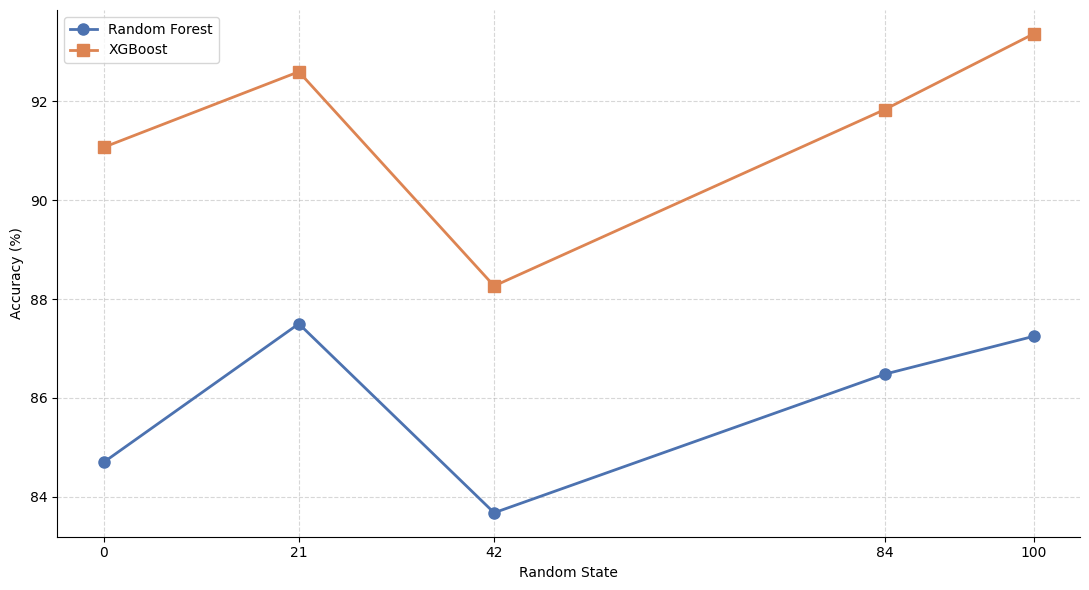

In [ ]:
# Visualisasi Akurasi Random State per Model
fig, ax = plt.subplots(figsize=(11, 6))

# Plot garis Random Forest
ax.plot(df_robustness['Random_State'], df_robustness['RF_Accuracy'] * 100,
        marker='o', markersize=8, linewidth=2, color='#4C72B0', label='Random Forest')

# Plot garis XGBoost
ax.plot(df_robustness['Random_State'], df_robustness['XGB_Accuracy'] * 100,
        marker='s', markersize=8, linewidth=2, color='#DD8452', label='XGBoost')

ax.set_xlabel('Random State')
ax.set_ylabel('Accuracy (%)')
ax.set_xticks(df_robustness['Random_State'])
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figure_3_robustness.png', dpi=350, bbox_inches='tight')
plt.show()

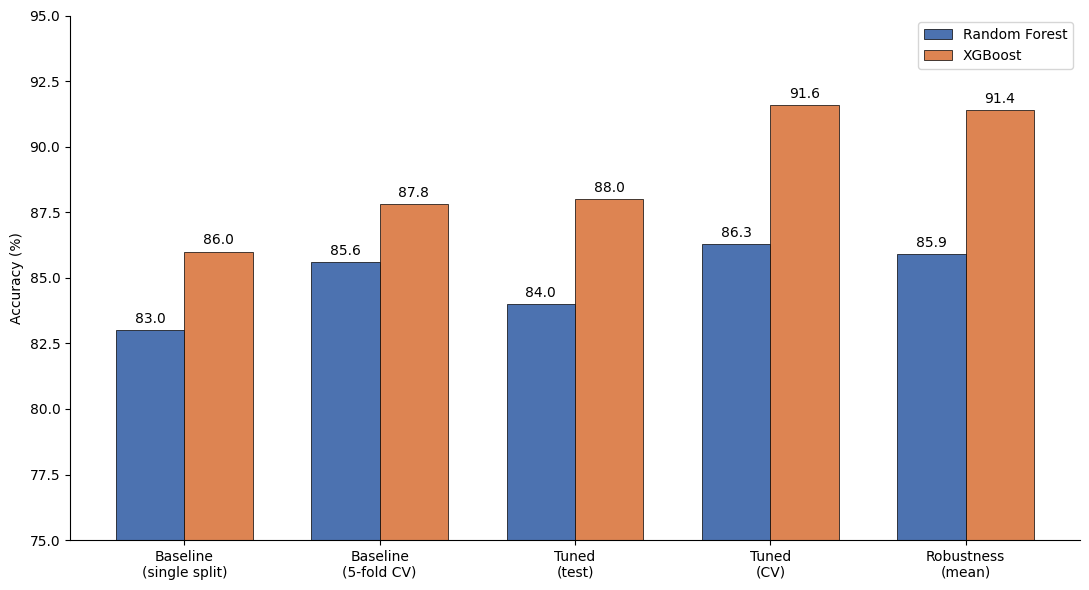

In [ ]:
# Visualisasi 4 Methode
tahap = ['Baseline\n(single split)', 'Baseline\n(5-fold CV)', 'Tuned\n(test)', 'Tuned\n(CV)', 'Robustness\n(mean)']
akurasi_rf = [83.0, 85.6, 84.0, 86.3, 85.9]
akurasi_xgb = [86.0, 87.8, 88.0, 91.6, 91.4]

x = np.arange(len(tahap))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
bars_rf = ax.bar(x - width/2, akurasi_rf, width, label='Random Forest', color='#4C72B0', edgecolor='black', linewidth=0.5)
bars_xgb = ax.bar(x + width/2, akurasi_xgb, width, label='XGBoost', color='#DD8452', edgecolor='black', linewidth=0.5)

# Tambahkan label angka di atas tiap bar
for bars in [bars_rf, bars_xgb]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Accuracy (%)')
ax.set_ylim(75, 95)
ax.set_xticks(x)
ax.set_xticklabels(tahap)
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figure_2_comparison.png', dpi=350, bbox_inches='tight')
plt.show()

## 13. Explainable AI dengan SHAP

Seluruh analisis SHAP dikumpulkan dalam satu bagian ini secara berurutan: instalasi & perhitungan nilai SHAP, ringkasan pengaruh fitur (summary & bar plot), studi kasus individu (waterfall plot), analisis hubungan detail fitur Age (dependence plot), hingga perbandingan feature importance antara Random Forest dan XGBoost.

In [ ]:
!pip install shap -q
import shap

In [ ]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

print("Shape SHAP values:", shap_values.shape)

Shape SHAP values: (392, 18)


In [ ]:
# Buat explainer SHAP khusus untuk model Random Forest
explainer_rf = shap.TreeExplainer(rf_model)

# Hitung nilai SHAP untuk seluruh data test menggunakan model Random Forest
shap_values_rf = explainer_rf.shap_values(X_test)

# Ubah hasilnya menjadi numpy array agar bentuknya (shape) bisa diperiksa dengan mudah
shap_values_rf_arr = np.array(shap_values_rf)

# Untuk RandomForestClassifier, hasilnya berbentuk 3 dimensi: (jumlah_sampel, jumlah_fitur, jumlah_kelas)
# Karena kita hanya tertarik pada kelas 1 (Berisiko), ambil irisan array di kelas tersebut (index 1)
shap_values_rf_plot = shap_values_rf_arr[:, :, 1]

# Cek ulang bentuk array setelah diseleksi, harus jadi 2 dimensi: (jumlah_sampel, jumlah_fitur)
print("Shape setelah diperbaiki:", shap_values_rf_plot.shape)

Shape setelah diperbaiki: (392, 18)


### 13.1 SHAP Summary Plot (Beeswarm)

A. XGBoost

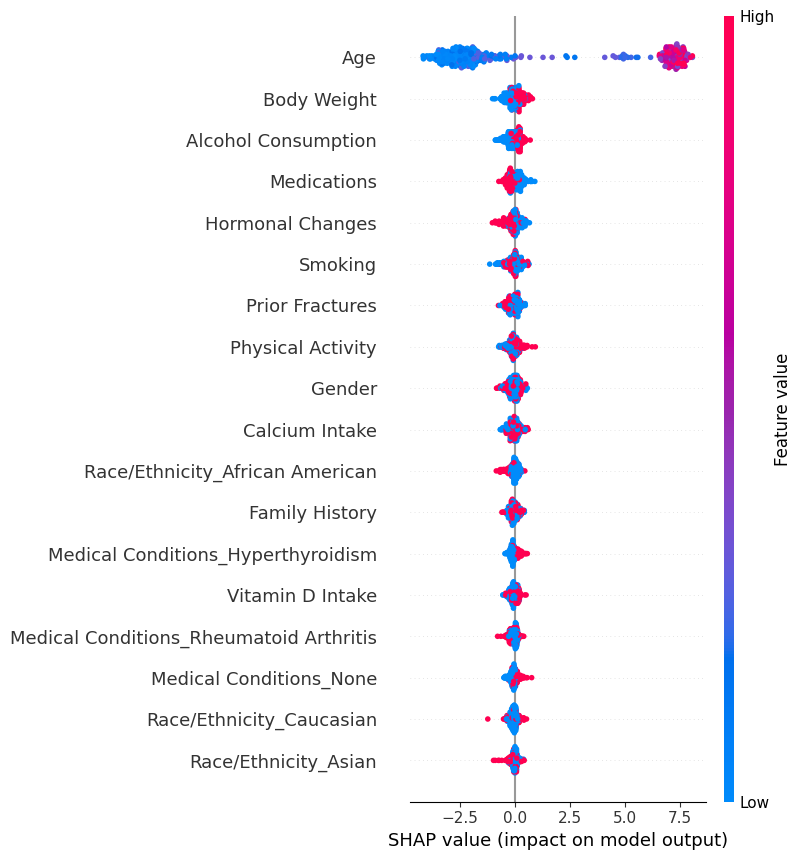

In [ ]:
shap.summary_plot(shap_values, X_test)

B. Random Forest

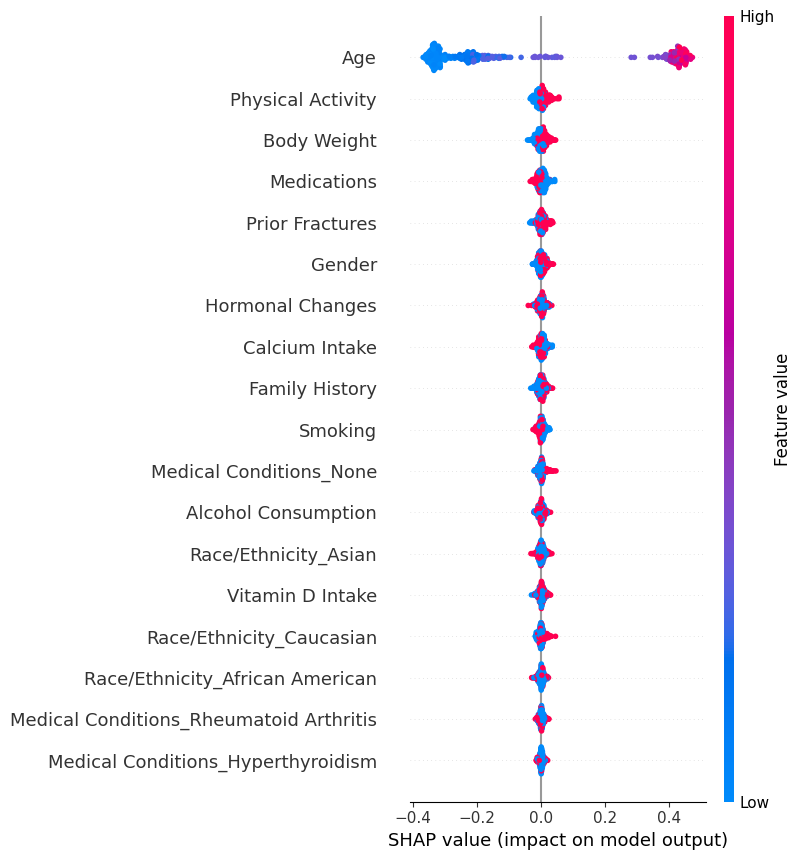

In [ ]:
shap.summary_plot(shap_values_rf_plot, X_test)

A. Perbandingan Random Forest dan XGBoost

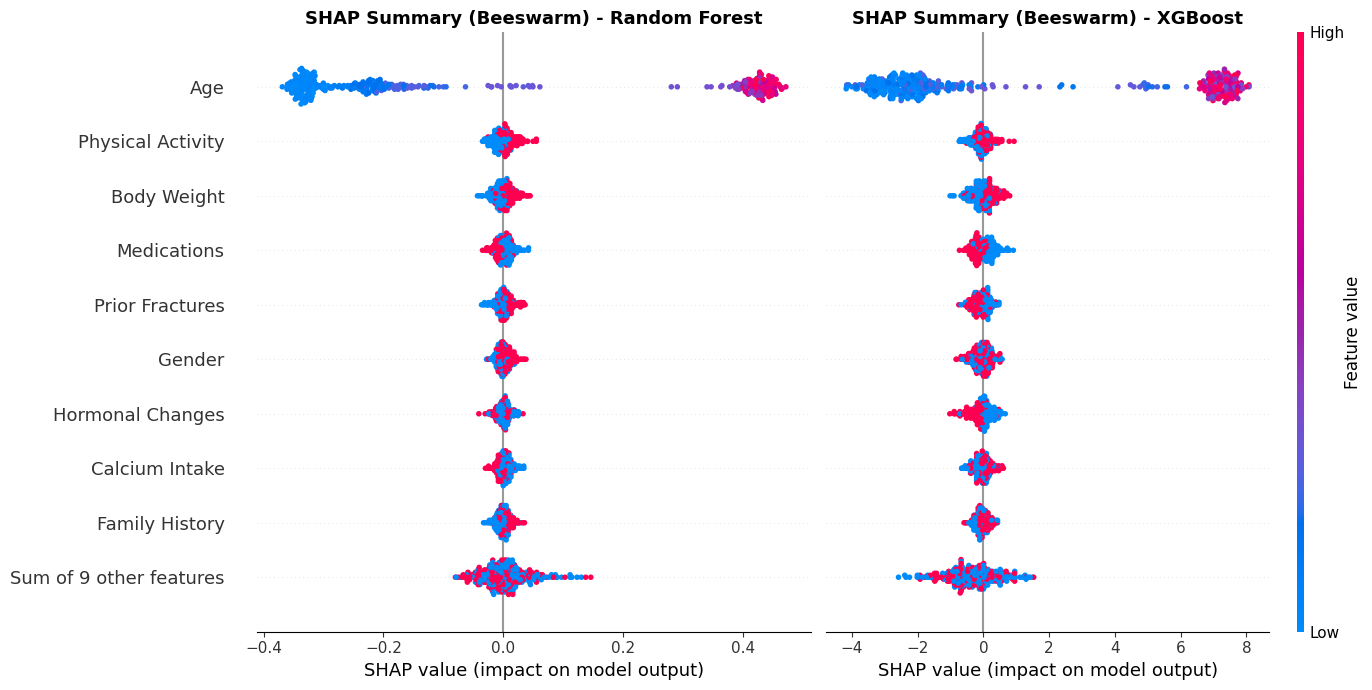

In [ ]:
# Bungkus nilai SHAP jadi Explanation object (dibutuhkan oleh API beeswarm terbaru)
exp_rf = shap.Explanation(values=shap_values_rf_plot, data=X_test.values, feature_names=X_test.columns.tolist())
exp_xgb = shap.Explanation(values=shap_values, data=X_test.values, feature_names=X_test.columns.tolist())

# Urutkan SEMUA fitur berdasarkan importance Random Forest (dari yang terbesar)
# Urutan ini dipakai SAMA untuk kedua plot, supaya nama fitur cukup 1x tampil di kiri
importance_rf = np.abs(shap_values_rf_plot).mean(axis=0)
order = np.argsort(importance_rf)[::-1]  # urutan lengkap, JANGAN dipotong di sini

# Buat 2 beeswarm plot berdampingan, berbagi sumbu-y yang sama (tampilkan TOP 10 lewat max_display)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

shap.plots.beeswarm(exp_rf, order=order, max_display=10, ax=axes[0], show=False, color_bar=False, plot_size=None)
axes[0].set_title('SHAP Summary (Beeswarm) - Random Forest', fontsize=13, fontweight='bold')

shap.plots.beeswarm(exp_xgb, order=order, max_display=10, ax=axes[1], show=False, color_bar=True, plot_size=None)
axes[1].set_title('SHAP Summary (Beeswarm) - XGBoost', fontsize=13, fontweight='bold')
axes[1].set_yticklabels([])  # sembunyikan label fitur di kanan (sudah ada di kiri)
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('figure_5_shap_beeswarm.png', dpi=350, bbox_inches='tight')
plt.show()

In [ ]:
# Hitung rata-rata NILAI SHAP (signed, TANPA absolut) tiap fitur untuk Random Forest
# Positif = rata-rata mendorong ke arah "Berisiko", Negatif = mendorong ke arah "Tidak Berisiko"
mean_shap_rf = shap_values_rf_plot.mean(axis=0)

# Hitung rata-rata nilai SHAP (signed) tiap fitur untuk XGBoost
mean_shap_xgb = shap_values.mean(axis=0)

# Cek ukuran array, harus sama-sama sepanjang jumlah fitur (18)
print("Shape mean_shap_rf:", mean_shap_rf.shape)
print("Shape mean_shap_xgb:", mean_shap_xgb.shape)

# Gabungkan kedua hasil ke dalam satu tabel perbandingan arah pengaruh
df_direction_compare = pd.DataFrame({
    'Feature': X_test.columns,
    'RF_Mean_SHAP': mean_shap_rf,
    'RF_Arah': np.where(mean_shap_rf > 0, 'Berisiko', 'Tidak Berisiko'),
    'XGB_Mean_SHAP': mean_shap_xgb,
    'XGB_Arah': np.where(mean_shap_xgb > 0, 'Berisiko', 'Tidak Berisiko')
}).sort_values('XGB_Mean_SHAP', key=abs, ascending=False)  # urutkan dari yang paling berpengaruh

print(df_direction_compare)

Shape mean_shap_rf: (18,)
Shape mean_shap_xgb: (18,)
                                    Feature  RF_Mean_SHAP         RF_Arah  \
0                                       Age     -0.025423  Tidak Berisiko   
11                          Prior Fractures      0.001115        Berisiko   
17  Medical Conditions_Rheumatoid Arthritis      0.000192        Berisiko   
9                       Alcohol Consumption      0.000248        Berisiko   
7                         Physical Activity      0.000266        Berisiko   
14                 Race/Ethnicity_Caucasian     -0.000024  Tidak Berisiko   
12          Race/Ethnicity_African American     -0.000591  Tidak Berisiko   
8                                   Smoking      0.000721        Berisiko   
5                            Calcium Intake      0.001155        Berisiko   
1                                    Gender      0.001413        Berisiko   
2                          Hormonal Changes      0.000697        Berisiko   
3                      

### 13.2 SHAP Feature Importance / Bar Plot

A. XGBoost

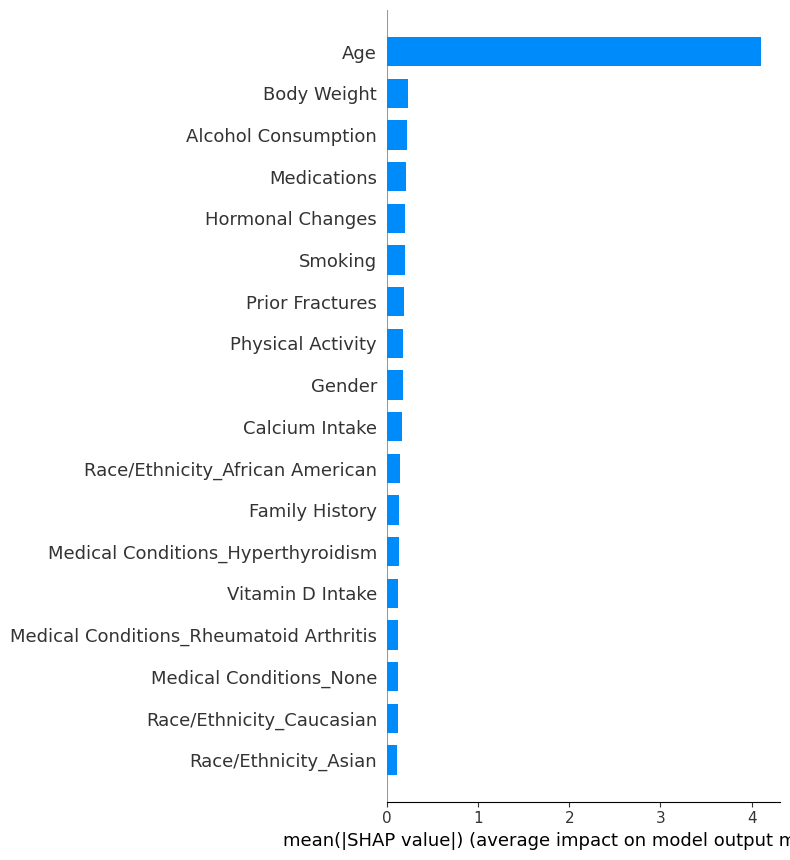

In [ ]:
shap.summary_plot(shap_values, X_test, plot_type='bar')

B. Random Forest

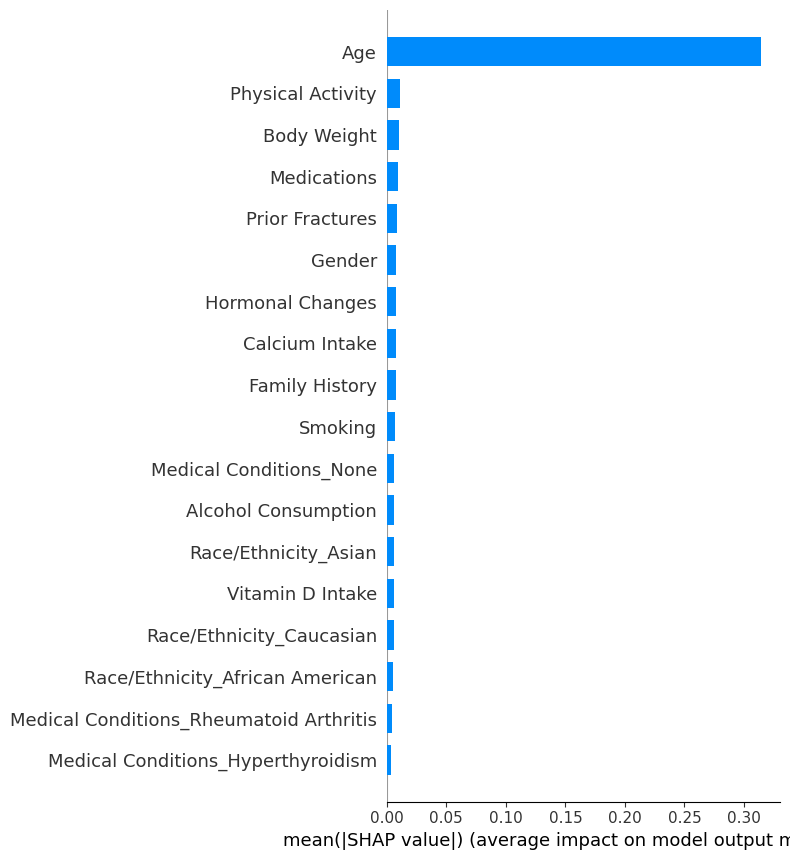

In [ ]:
shap.summary_plot(shap_values_rf_plot, X_test, plot_type='bar')

### 13.3 Perbandingan SHAP: Random Forest vs XGBoost

Menghitung dan membandingkan nilai SHAP dari kedua model untuk melihat apakah keduanya sepakat mengenai fitur mana yang paling berpengaruh.

In [ ]:
# Hitung rata-rata NILAI ABSOLUT SHAP tiap fitur untuk Random Forest
# (dijadikan absolut karena kita hanya peduli SEBERAPA BESAR pengaruhnya, bukan arahnya)
importance_rf = np.abs(shap_values_rf_plot).mean(axis=0)

# Hitung rata-rata nilai absolut SHAP tiap fitur untuk XGBoost (sudah dihitung sebelumnya di shap_values)
importance_xgb = np.abs(shap_values).mean(axis=0)

# Cek ukuran array, harus sama-sama sepanjang jumlah fitur (18)
print("Shape importance_rf:", importance_rf.shape)
print("Shape importance_xgb:", importance_xgb.shape)

# Gabungkan kedua hasil importance ke dalam satu tabel perbandingan
df_importance_compare = pd.DataFrame({
    'Feature': X_test.columns,       # nama tiap fitur
    'RF_Importance': importance_rf,  # tingkat kepentingan fitur menurut Random Forest
    'XGB_Importance': importance_xgb # tingkat kepentingan fitur menurut XGBoost
}).sort_values('XGB_Importance', ascending=False)  # urutkan dari yang paling berpengaruh

print(df_importance_compare)

Shape importance_rf: (18,)
Shape importance_xgb: (18,)
                                    Feature  RF_Importance  XGB_Importance
0                                       Age       0.314457        4.104825
4                               Body Weight       0.010451        0.233708
9                       Alcohol Consumption       0.006300        0.217784
10                              Medications       0.009093        0.216626
2                          Hormonal Changes       0.007742        0.203798
8                                   Smoking       0.006769        0.198487
11                          Prior Fractures       0.008341        0.185917
7                         Physical Activity       0.011230        0.183715
1                                    Gender       0.008007        0.182062
5                            Calcium Intake       0.007553        0.165134
12          Race/Ethnicity_African American       0.005498        0.143625
3                            Family History  

In [ ]:
# Urutkan 10 fitur teratas berdasarkan importance Random Forest
# (urutan yang sama dipakai untuk kedua grafik)
top_n = 10
order_idx = np.argsort(importance_rf)[::-1][:top_n]
features_ordered = X_test.columns[order_idx].tolist()
importance_rf_ordered = importance_rf[order_idx]
importance_xgb_ordered = importance_xgb[order_idx]

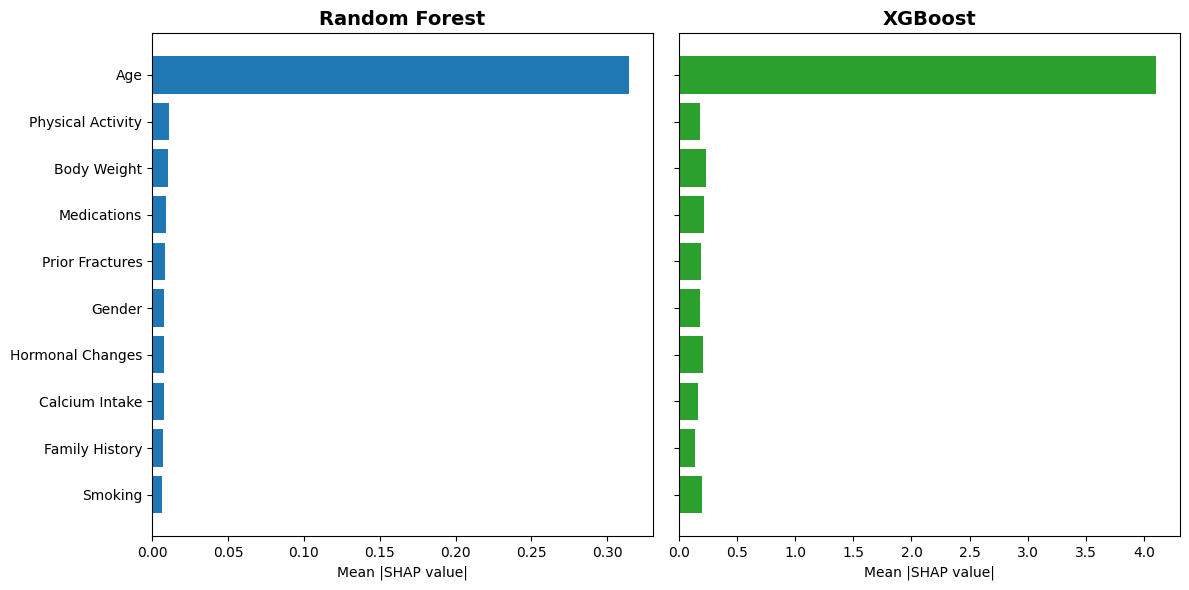

In [ ]:
# Buat 2 bar chart berdampingan dengan SUMBU-Y YANG DIBAGI (sharey=True)
# supaya nama fitur cuma muncul 1x di kiri, hemat tempat
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
y_pos = np.arange(len(features_ordered))

axes[0].barh(y_pos, importance_rf_ordered[::-1], color='#1f77b4')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(features_ordered[::-1])
axes[0].set_title('Random Forest', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Mean |SHAP value|')

axes[1].barh(y_pos, importance_xgb_ordered[::-1], color='#2ca02c')
axes[1].set_title('XGBoost', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Mean |SHAP value|')

plt.tight_layout()
plt.savefig('figure_4_shap_bar.png', dpi=350, bbox_inches='tight')
plt.show()

# **Lampiran: Demo Interpretasi Individual**

### L.1 SHAP Waterfall Plot — Studi Kasus Individu
Menggunakan data pasien dari dataset

**Kasus 1: Pasien diprediksi Berisiko (kelas 1), prediksi benar**

In [ ]:
# Ambil index pasien pertama yang diprediksi berisiko (kelas 1) di data test
risk_indices = np.where(y_pred_xgb == 1)[0]
sample_idx = risk_indices[0]

print("Index pasien:", sample_idx)
print("Data pasien:")
print(X_test.iloc[sample_idx])
print()
print("Prediksi model:", y_pred_xgb[sample_idx], "| Aktual:", y_test.iloc[sample_idx])

Index pasien: 1
Data pasien:
Age                                           27
Gender                                         1
Hormonal Changes                               1
Family History                                 1
Body Weight                                    1
Calcium Intake                                 1
Vitamin D Intake                               0
Physical Activity                              1
Smoking                                        0
Alcohol Consumption                            0
Medications                                    0
Prior Fractures                                0
Race/Ethnicity_African American            False
Race/Ethnicity_Asian                        True
Race/Ethnicity_Caucasian                   False
Medical Conditions_Hyperthyroidism         False
Medical Conditions_None                    False
Medical Conditions_Rheumatoid Arthritis     True
Name: 855, dtype: object

Prediksi model: 1 | Aktual: 1


A. XGBoost

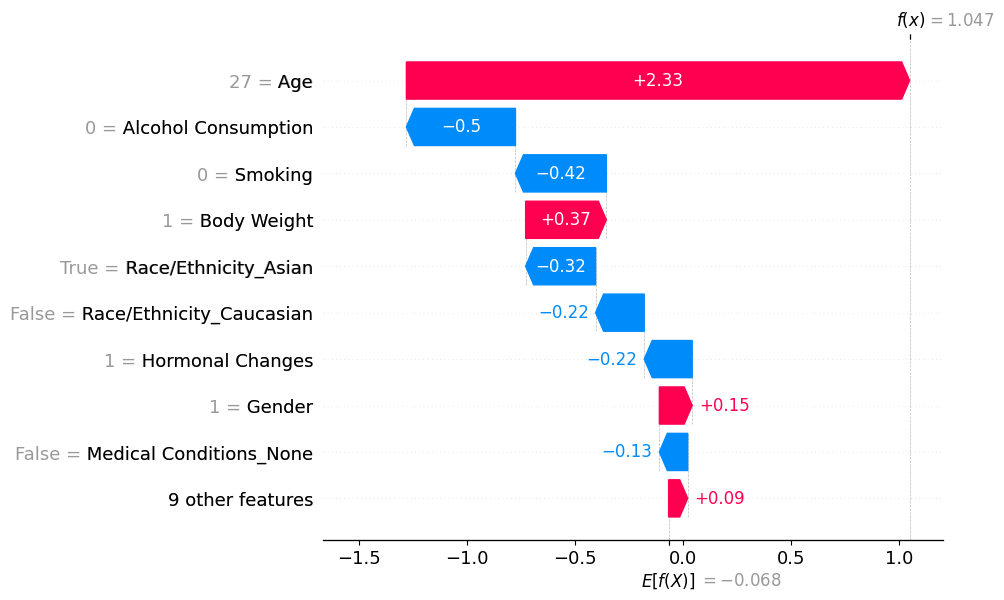

In [ ]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values[sample_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[sample_idx],
    feature_names=X_test.columns.tolist()
))

B. Random Forest

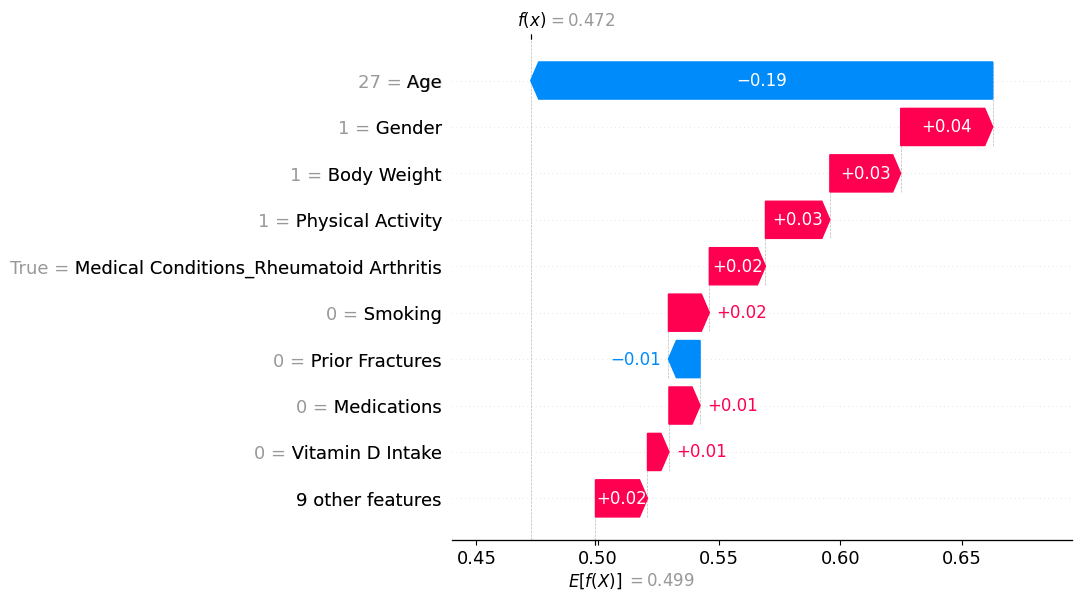

In [ ]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values_rf_plot[sample_idx],
    base_values=explainer_rf.expected_value[1],
    data=X_test.iloc[sample_idx],
    feature_names=X_test.columns.tolist()
))

**Kasus 2: Pasien diprediksi Tidak Berisiko (kelas 0) — memeriksa kasus yang salah prediksi (aktual = 1)**

A. XGBoost

Index pasien: 0
Prediksi model: 0 | Aktual: 1


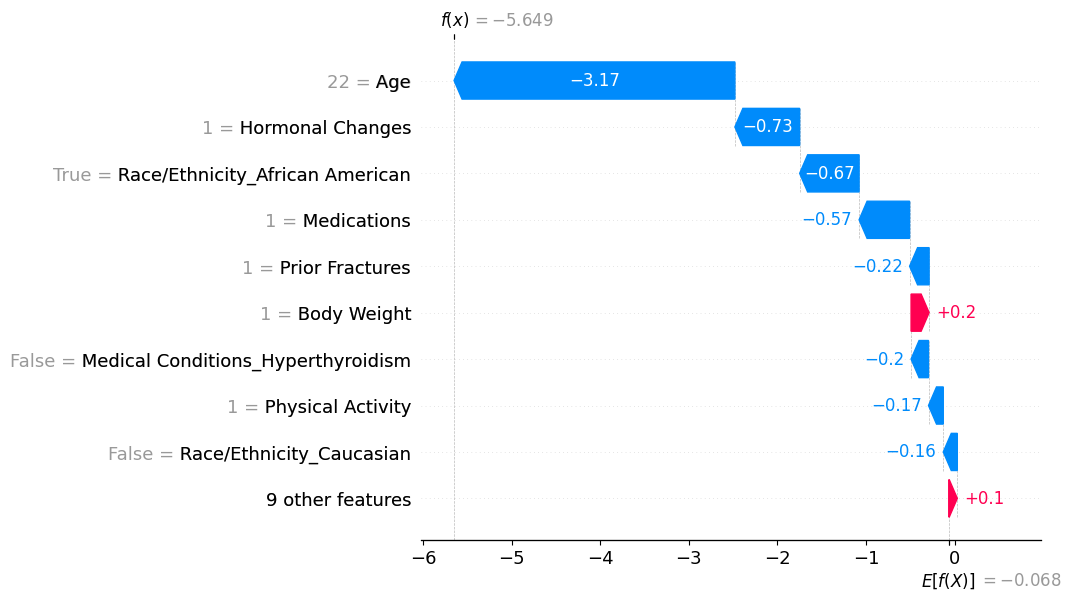

In [ ]:
norisk_indices = np.where(y_pred_xgb == 0)[0]
sample_idx2 = norisk_indices[0]

print("Index pasien:", sample_idx2)
print("Prediksi model:", y_pred_xgb[sample_idx2], "| Aktual:", y_test.iloc[sample_idx2])

shap.plots.waterfall(shap.Explanation(
    values=shap_values[sample_idx2],
    base_values=explainer.expected_value,
    data=X_test.iloc[sample_idx2],
    feature_names=X_test.columns.tolist()
))

B. Random Forest

Index pasien: 0
Prediksi model: 0 | Aktual: 1


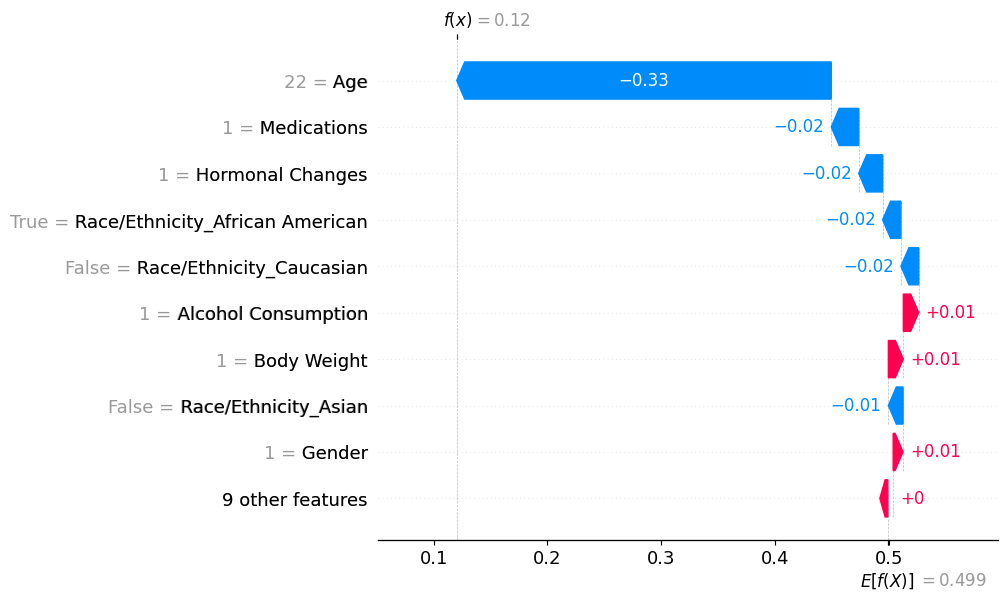

In [ ]:
norisk_indices_rf = np.where(y_pred_rf == 0)[0]
sample_idx2_rf = norisk_indices_rf[0]

print("Index pasien:", sample_idx2_rf)
print("Prediksi model:", y_pred_rf[sample_idx2_rf], "| Aktual:", y_test.iloc[sample_idx2_rf])

shap.plots.waterfall(shap.Explanation(
    values=shap_values_rf_plot[sample_idx2_rf],
    base_values=explainer_rf.expected_value[1],
    data=X_test.iloc[sample_idx2_rf],
    feature_names=X_test.columns.tolist()
))

### L.2 SHAP Dependence Plot — Fitur Age

Menunjukkan hubungan detail antara nilai usia (Age) dan pengaruhnya terhadap prediksi risiko osteoporosis, untuk melihat pada usia berapa risiko mulai meningkat tajam.

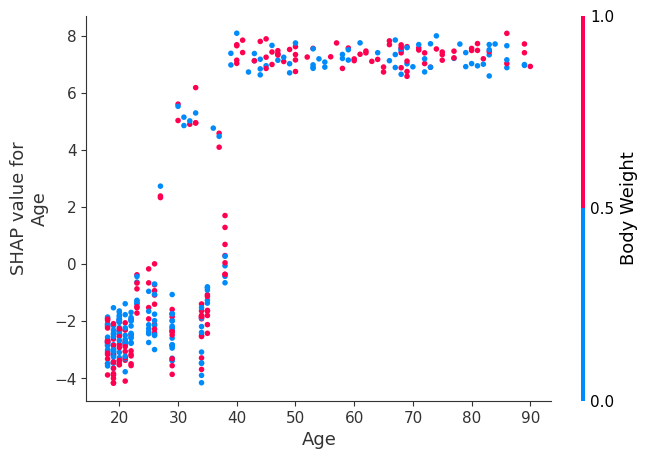

In [ ]:
# shap.dependence_plot menunjukkan hubungan antara NILAI suatu fitur (sumbu X)
# dengan PENGARUHNYA terhadap prediksi model / nilai SHAP (sumbu Y)
# "Age"       -> fitur yang ingin dianalisis
# shap_values -> nilai SHAP yang sudah dihitung sebelumnya (dari model XGBoost)
# X_test      -> data test yang sesuai dengan shap_values tersebut
shap.dependence_plot("Age", shap_values, X_test)

### L.3 Studi Kasus: Simulasi Pasien Baru (Belum Diketahui Status Osteoporosisnya)

In [ ]:
# Buat data pasien baru secara manual (dibuat sendiri, bukan dari dataset)
# Angka/kategori di bawah ini merepresentasikan kondisi pasien hipotetis:
# - Usia 65 tahun, Wanita, sudah pascamenopause, ada riwayat keluarga osteoporosis, dst
pasien_baru = pd.DataFrame([{
    'Age': 65,
    'Gender': 0,                  # 0 = Female (lihat tabel keterangan encoding)
    'Hormonal Changes': 1,        # 1 = Postmenopausal
    'Family History': 1,          # 1 = Yes
    'Body Weight': 1,             # 1 = Underweight
    'Calcium Intake': 1,          # 1 = Low
    'Vitamin D Intake': 0,        # 0 = Insufficient
    'Physical Activity': 1,       # 1 = Sedentary
    'Smoking': 0,                 # 0 = No
    'Alcohol Consumption': 0,     # 0 = Moderate
    'Medications': 1,             # 1 = None
    'Prior Fractures': 0,         # 0 = No
    # Kolom hasil One-Hot Encoding untuk Race/Ethnicity dan Medical Conditions,
    # perlu diisi False semua kecuali kategori yang sesuai kondisi pasien
}])

# Pastikan urutan & jumlah kolom SAMA PERSIS dengan X_train,
# kolom yang belum diisi di atas (hasil one-hot) otomatis diisi 0/False
pasien_baru = pasien_baru.reindex(columns=X_train.columns, fill_value=False)

print("Data pasien baru:")
print(pasien_baru)

Data pasien baru:
   Age  Gender  Hormonal Changes  Family History  Body Weight  Calcium Intake  \
0   65       0                 1               1            1               1   

   Vitamin D Intake  Physical Activity  Smoking  Alcohol Consumption  \
0                 0                  1        0                    0   

   Medications  Prior Fractures  Race/Ethnicity_African American  \
0            1                0                            False   

   Race/Ethnicity_Asian  Race/Ethnicity_Caucasian  \
0                 False                     False   

   Medical Conditions_Hyperthyroidism  Medical Conditions_None  \
0                               False                    False   

   Medical Conditions_Rheumatoid Arthritis  
0                                    False  


A. XGBoost

In [ ]:
# Prediksi status osteoporosis pasien baru ini menggunakan model XGBoost yang sudah dilatih
prediksi = xgb_model.predict(pasien_baru)[0]
probabilitas = xgb_model.predict_proba(pasien_baru)[0]

label = "BERISIKO" if prediksi == 1 else "TIDAK BERISIKO"
print(f"Hasil prediksi: {label}")
print(f"Probabilitas -> Tidak Berisiko: {probabilitas[0]:.2%}, Berisiko: {probabilitas[1]:.2%}")

Hasil prediksi: BERISIKO
Probabilitas -> Tidak Berisiko: 0.19%, Berisiko: 99.81%


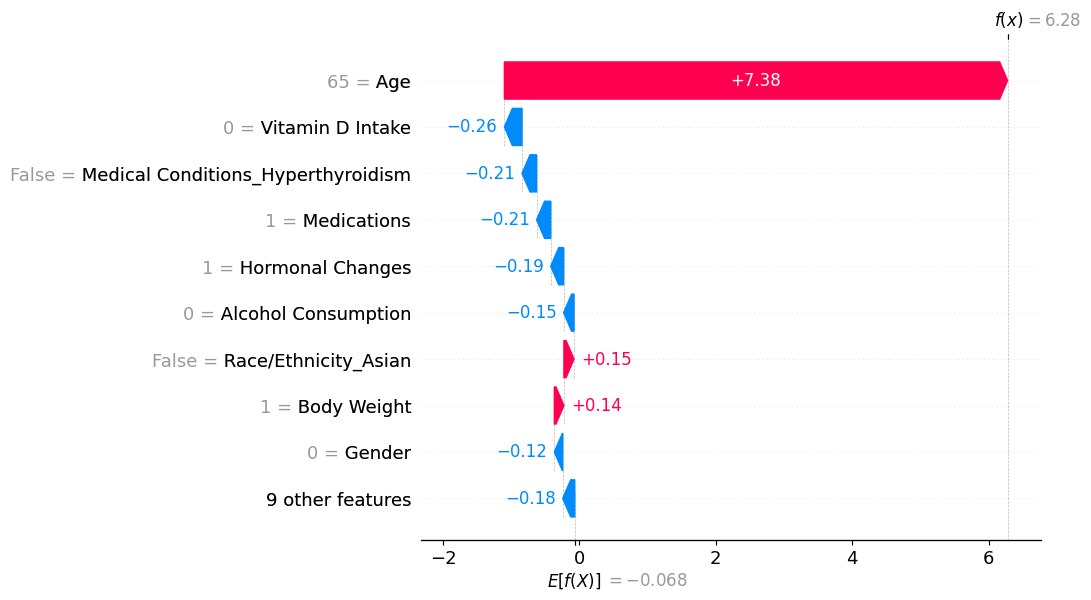

In [ ]:
# Menjelaskan KENAPA model memprediksi demikian, menggunakan SHAP waterfall plot
shap_values_pasien_baru = explainer.shap_values(pasien_baru)

shap.plots.waterfall(shap.Explanation(
    values=shap_values_pasien_baru[0],
    base_values=explainer.expected_value,
    data=pasien_baru.iloc[0],
    feature_names=pasien_baru.columns.tolist()
))

B. Random Forest

In [ ]:
# Prediksi status osteoporosis pasien baru ini menggunakan model Random Forest yang sudah dilatih
prediksi_rf = rf_model.predict(pasien_baru)[0]
probabilitas_rf = rf_model.predict_proba(pasien_baru)[0]

label_rf = "BERISIKO" if prediksi_rf == 1 else "TIDAK BERISIKO"
print(f"Hasil prediksi: {label_rf}")
print(f"Probabilitas -> Tidak Berisiko: {probabilitas_rf[0]:.2%}, Berisiko: {probabilitas_rf[1]:.2%}")

Hasil prediksi: BERISIKO
Probabilitas -> Tidak Berisiko: 7.90%, Berisiko: 92.10%


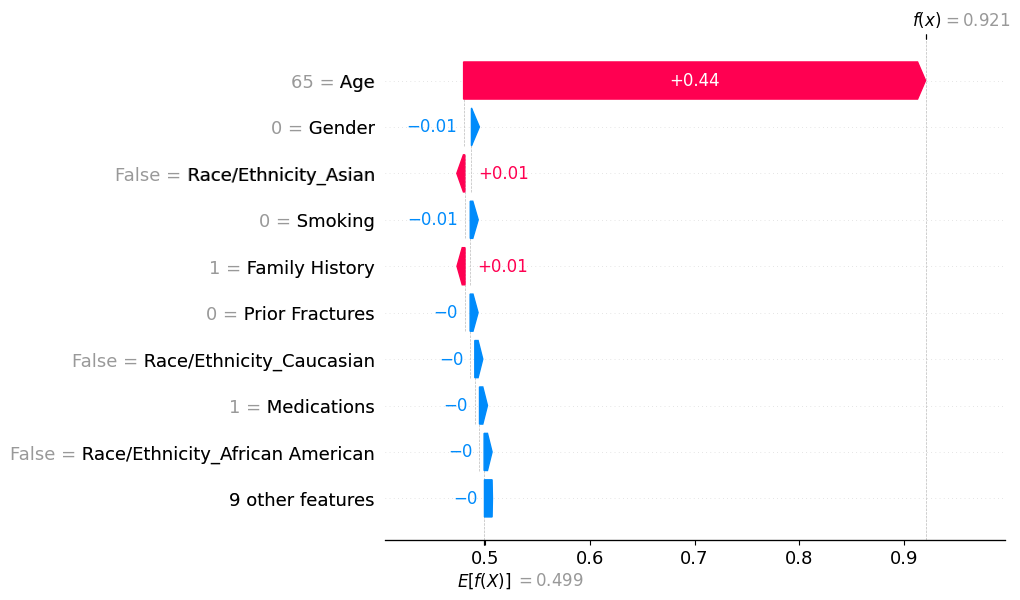

In [ ]:
# Menjelaskan KENAPA model memprediksi demikian, menggunakan SHAP waterfall plot (Random Forest)
shap_values_pasien_baru_rf = explainer_rf.shap_values(pasien_baru)

# Ubah ke numpy array dan ambil irisan kelas 1 (Berisiko), sama seperti proses shap_values_rf_plot
shap_values_pasien_baru_rf_arr = np.array(shap_values_pasien_baru_rf)[:, :, 1]

shap.plots.waterfall(shap.Explanation(
    values=shap_values_pasien_baru_rf_arr[0],
    base_values=explainer_rf.expected_value[1],
    data=pasien_baru.iloc[0],
    feature_names=pasien_baru.columns.tolist()
))

# **Analisis dan Kesimpulan**

### 1. Ringkasan Performa Model

| Tahap | Random Forest | XGBoost |
|---|---|---|
| Baseline (single split) | 83% | 86% |
| Baseline (5-fold CV) | 85.60% ± 1.70% | 87.79% ± 2.75% |
| Tuned (GridSearchCV) | 84% / CV: 86.27% | 88% / CV: 91.57% |
| Robustness (5 random state) | 85.92% ± 1.67% | 91.43% ± 1.96% |

XGBoost dengan parameter hasil tuning (`max_depth=3, learning_rate=0.1, n_estimators=100`) merupakan model dengan performa terbaik dan paling stabil, mencapai akurasi rata-rata ±91% pada pengujian dengan berbagai skema random state.

### 2. Catatan Mengenai Distribusi Kelas

Distribusi kelas target (Osteoporosis) pada dataset ini tercatat seimbang sempurna (979 berbanding 979). Hal ini kemungkinan besar merupakan hasil kurasi/penyeimbangan yang telah dilakukan oleh penyedia dataset di Kaggle, bukan proses yang dilakukan dalam penelitian ini.

### 3. Interpretasi SHAP

Hasil SHAP dari kedua model (Random Forest dan XGBoost) secara konsisten menunjukkan bahwa **Age (usia)** merupakan faktor paling dominan dalam memprediksi risiko osteoporosis, dengan nilai SHAP yang jauh melampaui seluruh fitur lainnya. Kesepakatan ini pada dua algoritma dengan mekanisme berbeda memperkuat validitas temuan, dan sejalan dengan pengetahuan medis mengenai penurunan kepadatan tulang seiring bertambahnya usia, khususnya pascamenopause (berkaitan dengan fitur *Hormonal Changes*).

Fitur-fitur lain seperti *Body Weight*, *Alcohol Consumption*, *Medications*, dan *Physical Activity* memberikan kontribusi lebih kecil namun tetap konsisten dengan faktor risiko osteoporosis pada literatur kesehatan.

### 4. Kesimpulan Sementara

1. Kedua model menunjukkan performa klasifikasi yang baik dan stabil, dengan XGBoost secara konsisten unggul dibandingkan Random Forest pada seluruh skema evaluasi.
2. Hyperparameter tuning berhasil meningkatkan performa kedua model secara signifikan, terutama pada XGBoost (CV score naik dari 87.79% menjadi 91.57%).
3. Usia merupakan prediktor risiko osteoporosis yang paling dominan, konsisten pada kedua model.
4. Pendekatan *Explainable AI* (SHAP) berhasil memberikan interpretasi yang transparan terhadap prediksi model, baik pada kasus yang benar maupun yang salah diprediksi.

### 5. Keterbatasan dan Saran Penelitian Lanjutan

- Dataset yang digunakan sudah seimbang secara kelas; disarankan menguji model pada dataset dengan distribusi kelas yang lebih mencerminkan prevalensi osteoporosis di populasi nyata.
- Penelitian lanjutan dapat mempertimbangkan penambahan variabel klinis kuantitatif (misalnya hasil pemindaian kepadatan tulang/BMD).
- Analisis SHAP pada bagian ini menjelaskan model XGBoost baseline (sebelum tuning); penelitian lanjutan dapat mengulang analisis SHAP pada model hasil tuning (`xgb_model_tuned`) untuk melihat apakah pola interpretasi tetap konsisten.
